# Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp

# Global parameters
A = np.array([[1.0, 1.0],
              [4.0, -2.0]])   # sedlo iz pripravljalne naloge
x0_pos = [2.0, -3.0]          # posebna zacetna tocka
meja = 3.0                    # obmocje [-meja, meja]^2
t_max = 10.0

rtol, atol = 1e-10, 1e-12

# Funkcije

In [2]:
# Simbolno: sled, determinanta, lastni pari in analiticna resitev x(t) = exp(A t) x0
t = sp.symbols("t", real=True)
A_sym = sp.Matrix([[1, 1], [4, -2]])
tau_sym = A_sym.trace()
Delta_sym = A_sym.det()
eig_sym = A_sym.eigenvects()  # [(lambda, krat., [v]), ...]

x_an = sp.simplify((A_sym * t).exp() * sp.Matrix(x0_pos).applyfunc(sp.nsimplify))
x_an_np = sp.lambdify(t, x_an, "numpy")

In [3]:
def rhs_lin(t, y, A):
    return A @ y

def izven(t, y, *args):
    # ustavi integracijo, ko trajektorija zapusti obmocje
    return meja + 0.5 - np.max(np.abs(y))
izven.terminal = True

def trajektorija(rhs, y0, t_max, args=()):
    # naprej in nazaj v casu
    deli = []
    for smer in (1, -1):
        sol = solve_ivp(rhs, (0, smer * t_max), y0, args=args, events=izven,
                        rtol=rtol, atol=atol, max_step=0.02)
        deli.append(sol.y)
    return np.hstack([deli[1][:, ::-1], deli[0]])

def klasifikacija(A, eps=1e-12):
    tau, Delta = np.trace(A), np.linalg.det(A)
    D = tau**2 - 4 * Delta
    if Delta < -eps:
        return "sedlo"
    if abs(Delta) < eps:
        return "degenerirano (Delta = 0)"
    if abs(tau) < eps:
        return "center"
    if D > eps:
        return "stabilen vozel" if tau < 0 else "nestabilen vozel"
    if D < -eps:
        return "stabilno gorišče" if tau < 0 else "nestabilno gorišče"
    return "degeneriran vozel"

def fazni_portret(ax, A, zacetne, naslov=""):
    xs = np.linspace(-meja, meja, 40)
    X, Y = np.meshgrid(xs, xs)
    U = A[0, 0] * X + A[0, 1] * Y
    V = A[1, 0] * X + A[1, 1] * Y
    ax.streamplot(X, Y, U, V, color="lightgray", density=1.2, linewidth=0.8)

    # invariantni premici (samo za realne lastne vrednosti)
    lam, vec = np.linalg.eig(A)
    if np.all(np.isreal(lam)):
        s = np.linspace(-2 * meja, 2 * meja, 2)
        for l, v, c in zip(lam.real, vec.real.T, ["C3", "C0"]):
            ax.plot(s * v[0], s * v[1], "--", color=c, linewidth=1.5, label=rf"$\lambda = {l:+.2f}$")

    for y0 in zacetne:
        tr = trajektorija(rhs_lin, y0, t_max, args=(A,))
        ax.plot(tr[0], tr[1], color="black", linewidth=1)
        ax.plot(*y0, "o", color="black", markersize=3)

    ax.plot(0, 0, "o", color="red", markersize=5)
    ax.set_xlim(-meja, meja)
    ax.set_ylim(-meja, meja)
    ax.set_aspect("equal")
    ax.set_xlabel("$x$", fontsize=14)
    ax.set_ylabel("$y$", fontsize=14)
    ax.set_title(naslov)
    if np.all(np.isreal(lam)):
        ax.legend(loc="upper left")

# Testno območje

In [4]:
# Pripravljalna naloga
display(sp.Eq(sp.Symbol("A"), A_sym, evaluate=False))
print(f"tau = {tau_sym},  Delta = {Delta_sym},  D = {tau_sym**2 - 4 * Delta_sym}")
for lam_i, _, v_i in eig_sym:
    display(sp.Eq(sp.Symbol("lambda"), lam_i), sp.Eq(sp.Symbol("v"), v_i[0], evaluate=False))
print("Tip ravnotezja:", klasifikacija(A))
display(sp.Eq(sp.Matrix(["x(t)", "y(t)"]), x_an, evaluate=False))

Eq(A, Matrix([
[1,  1],
[4, -2]]))

tau = -1,  Delta = -6,  D = 25


Eq(lambda, -3)

Eq(v, Matrix([
[-1/4],
[   1]]))

Eq(lambda, 2)

Eq(v, Matrix([
[1],
[1]]))

Tip ravnotezja: sedlo


Eq(Matrix([
[x(t)],
[y(t)]]), Matrix([
[(exp(5*t) + 1)*exp(-3*t)],
[(exp(5*t) - 4)*exp(-3*t)]]))

In [5]:
# Kontrola: analiticna vs. numericna resitev pri t = 1
sol = solve_ivp(rhs_lin, (0, 1), x0_pos, args=(A,), rtol=rtol, atol=atol)
print("numericno: ", sol.y[:, -1])
print("analiticno:", x_an_np(1.0).ravel())

numericno:  [7.43884317 7.18990783]
analiticno: [7.43884317 7.18990783]


# Naloga 1

In [6]:
lam, vec = np.linalg.eig(A)  # stolpci vec so normirani lastni vektorji

for i in range(2):
    l, v = lam[i], vec[:, i]
    # pripadajoc analiticni vektor, normiran
    v_an = [np.array(vs[0], dtype=float).ravel() for ls, _, vs in eig_sym if abs(float(ls) - l) < 1e-9][0]
    v_an /= np.linalg.norm(v_an)
    print(f"lambda = {l:+.6f}, v = [{v[0]:+.6f}, {v[1]:+.6f}], "
          f"|v . v_an| = {abs(v @ v_an):.12f}, |A v - lambda v| = {np.linalg.norm(A @ v - l * v):.1e}")

lambda = +2.000000+0.000000j, v = [+0.707107+0.000000j, +0.707107+0.000000j], |v . v_an| = 1.000000000000, |A v - lambda v| = 0.0e+00
lambda = -3.000000+0.000000j, v = [-0.242536+0.000000j, +0.970143+0.000000j], |v . v_an| = 1.000000000000, |A v - lambda v| = 0.0e+00


# Naloga 2

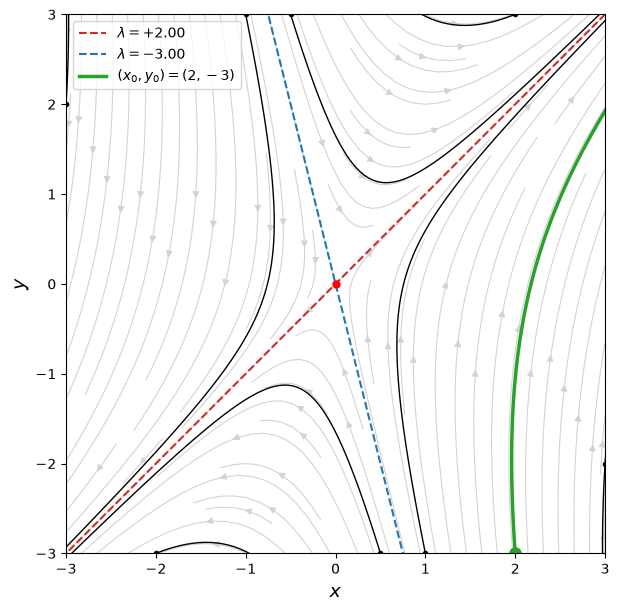

In [7]:
zacetne = [(0.5, -3), (1, -3), (-0.5, 3), (-1, 3), (-3, 2), (3, -2), (-2, -3), (2, 3)]

fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(111)
fazni_portret(ax, A, zacetne)

# posebna trajektorija (2, -3)
tr = trajektorija(rhs_lin, x0_pos, t_max, args=(A,))
ax.plot(tr[0], tr[1], color="C2", linewidth=2.5, label=r"$(x_0, y_0) = (2, -3)$")
ax.plot(*x0_pos, "o", color="C2", markersize=8)
ax.legend(loc="upper left")
plt.show()

# Naloga 3

In [8]:
matrike = {
    "Sedlo": A,
    "Stabilni vozel": np.array([[-3.0, 1.0], [1.0, -3.0]]),
    "Stabilno gorišče": np.array([[-1.0, 2.0], [-2.0, -1.0]]),
    "Center": np.array([[0.0, 1.0], [-4.0, 0.0]]),
}

print(f"{'tip':18s} {'A':>28s} {'tau':>5s} {'Delta':>6s} {'D':>6s}   lambda")
for ime, M in matrike.items():
    tau, Delta = np.trace(M), np.linalg.det(M)
    lam = np.linalg.eigvals(M)
    print(f"{ime:18s} {str(M.tolist()):>28s} {tau:5.1f} {Delta:6.1f} {tau**2 - 4 * Delta:6.1f}   "
          f"{np.round(lam, 3)}  -> {klasifikacija(M)}")

tip                                           A   tau  Delta      D   lambda
Sedlo                 [[1.0, 1.0], [4.0, -2.0]]  -1.0   -6.0   25.0   [ 2.+0.j -3.+0.j]  -> sedlo
Stabilni vozel       [[-3.0, 1.0], [1.0, -3.0]]  -6.0    8.0    4.0   [-2.+0.j -4.+0.j]  -> stabilen vozel
Stabilno gorišče    [[-1.0, 2.0], [-2.0, -1.0]]  -2.0    5.0  -16.0   [-1.+2.j -1.-2.j]  -> stabilno gorišče
Center                [[0.0, 1.0], [-4.0, 0.0]]   0.0    4.0  -16.0   [0.+2.j 0.-2.j]  -> center


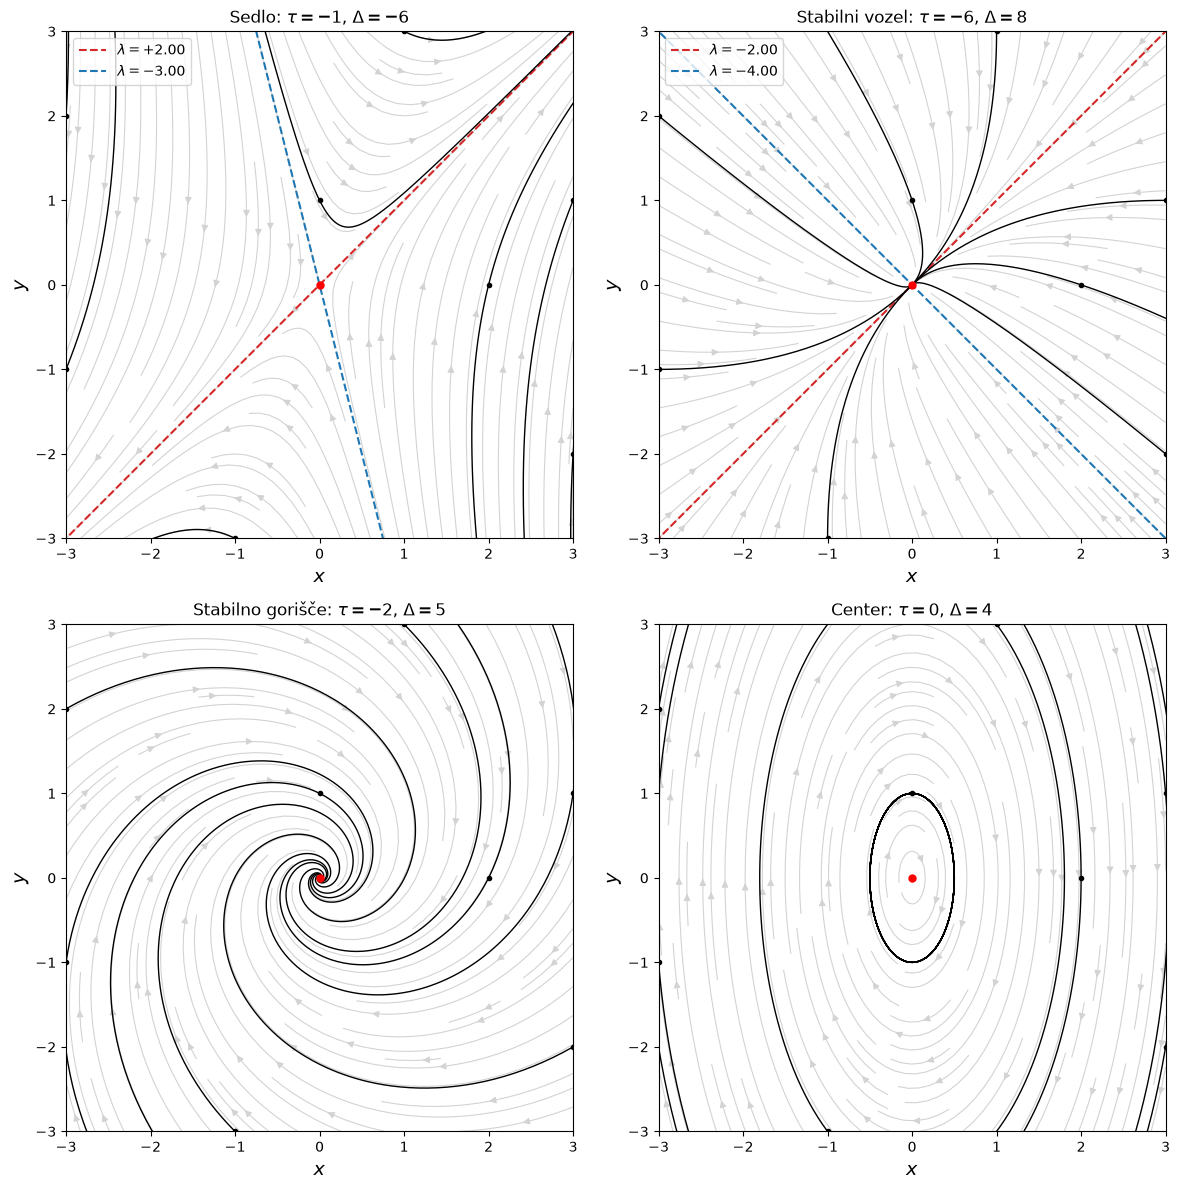

In [9]:
zacetne_3 = [(3, 1), (-3, -1), (1, 3), (-1, -3), (3, -2), (-3, 2), (2, 0), (0, 1)]

fig = plt.figure(figsize=(12, 12))
for i, (ime, M) in enumerate(matrike.items()):
    ax = fig.add_subplot(2, 2, i + 1)
    fazni_portret(ax, M, zacetne_3, rf"{ime}: $\tau = {np.trace(M):.0f}$, $\Delta = {np.linalg.det(M):.0f}$")
plt.tight_layout()
plt.show()

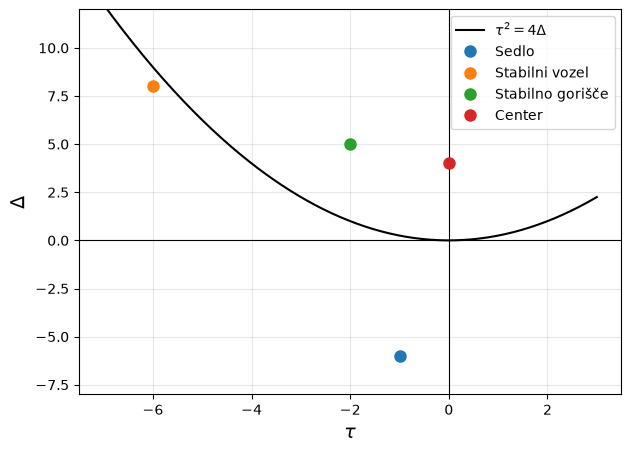

In [10]:
# Ravnina (tau, Delta)
tau_os = np.linspace(-7, 3, 300)

fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(111)
ax.plot(tau_os, tau_os**2 / 4, color="black", label=r"$\tau^2 = 4\Delta$")
ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(0, color="black", linewidth=0.8)
for ime, M in matrike.items():
    ax.plot(np.trace(M), np.linalg.det(M), "o", markersize=8, label=ime)
ax.set_xlabel(r"$\tau$", fontsize=14)
ax.set_ylabel(r"$\Delta$", fontsize=14)
ax.set_ylim(-8, 12)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

# Razmislek 1

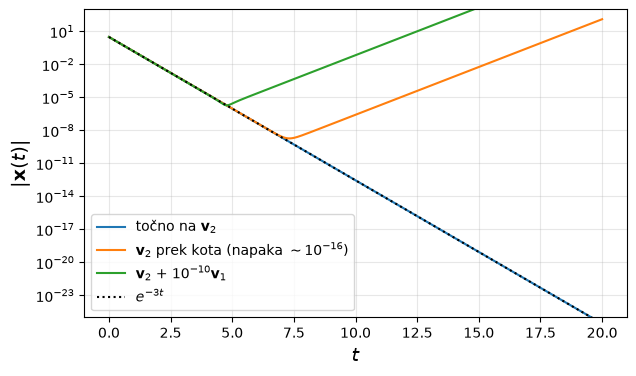

In [11]:
# Zacetek na stabilni smeri v2 = (1, -4):
#  - (0.75, -3) je v plavajoci vejici tocno na v2
#  - smer prek kota ima zaokrozitveno napako ~1e-16
#  - motnja 1e-10 vzdolz v1
v1, v2 = np.array([1.0, 1.0]), np.array([1.0, -4.0])
y_stab = 0.75 * v2
phi = np.arctan2(-4.0, 1.0)
y_kot = np.linalg.norm(y_stab) * np.array([np.cos(phi), np.sin(phi)])
t_r = np.linspace(0, 20, 2000)

fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(111)
for y0, oznaka in [(y_stab, r"točno na $\mathbf{v}_2$"),
                   (y_kot, r"$\mathbf{v}_2$ prek kota (napaka $\sim 10^{-16}$)"),
                   (y_stab + 1e-10 * v1, r"$\mathbf{v}_2$ + $10^{-10}\mathbf{v}_1$")]:
    sol = solve_ivp(rhs_lin, (0, 20), y0, args=(A,), t_eval=t_r, rtol=rtol, atol=1e-30)
    ax.plot(sol.t, np.linalg.norm(sol.y, axis=0), label=oznaka)
ax.plot(t_r, np.linalg.norm(y_stab) * np.exp(-3 * t_r), ":", color="black", label=r"$e^{-3t}$")
ax.set_yscale("log")
ax.set_ylim(1e-25, 1e3)
ax.set_xlabel("$t$", fontsize=14)
ax.set_ylabel(r"$|\mathbf{x}(t)|$", fontsize=14)
ax.legend()
ax.grid(alpha=0.3, which="both")
plt.show()

# Razmislek 2

In [12]:
# div f = Tr(J) za splosen linearen sistem
a, b, c, d, xs, ys = sp.symbols("a b c d x y")
f_lin = sp.Matrix([a * xs + b * ys, c * xs + d * ys])
print("div f =", sp.diff(f_lin[0], xs) + sp.diff(f_lin[1], ys))

# Hamiltonski oscilator: q' = dH/dp, p' = -dH/dq
q, p, m, k = sp.symbols("q p m k", positive=True)
H = p**2 / (2 * m) + k * q**2 / 2
f_ham = sp.Matrix([sp.diff(H, p), -sp.diff(H, q)])
J_ham = f_ham.jacobian([q, p])
display(J_ham)
print(f"tau = {J_ham.trace()},  Delta = {J_ham.det()}  -> center")

# Ploscina se skalira z det(exp(A t)) = exp(tau t)
print("det(exp(A t)) =", sp.simplify((A_sym * t).exp().det()))

div f = a + d


Matrix([
[ 0, 1/m],
[-k,   0]])

tau = 0,  Delta = k/m  -> center
det(exp(A t)) = exp(-t)


# Razmislek 3

In [13]:
# x' = y + eps x^3, y' = -x
eps = sp.symbols("epsilon", real=True)
f_nl = sp.Matrix([ys + eps * xs**3, -xs])
display(f_nl.jacobian([xs, ys]).subs({xs: 0, ys: 0}))       # linearizacija = center
print("d(r^2)/dt =", sp.expand(2 * xs * f_nl[0] + 2 * ys * f_nl[1]))

Matrix([
[ 0, 1],
[-1, 0]])

d(r^2)/dt = 2*epsilon*x**4


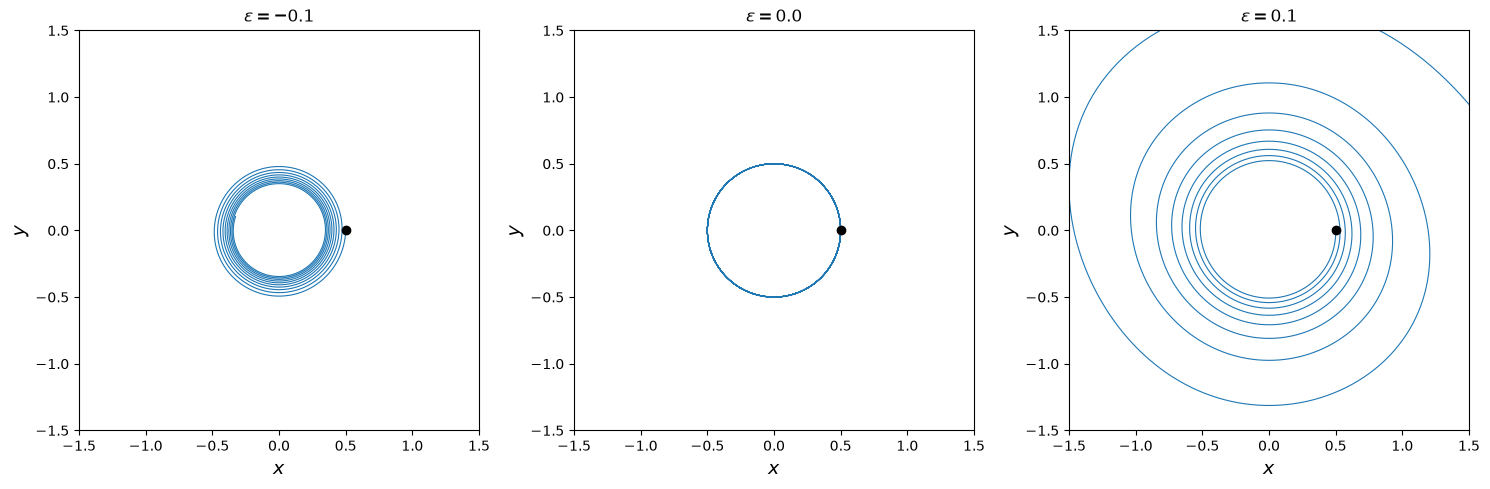

In [14]:
def rhs_nl(t, y, eps):
    return [y[1] + eps * y[0]**3, -y[0]]

fig = plt.figure(figsize=(15, 5))
for i, e in enumerate([-0.1, 0.0, 0.1]):
    ax = fig.add_subplot(1, 3, i + 1)
    sol = solve_ivp(rhs_nl, (0, 60), [0.5, 0.0], args=(e,), events=izven,
                    rtol=rtol, atol=atol, max_step=0.02)
    ax.plot(sol.y[0], sol.y[1], linewidth=0.8)
    ax.plot(0.5, 0, "o", color="black")
    ax.set_xlim(-1.5, 1.5)
    ax.set_ylim(-1.5, 1.5)
    ax.set_aspect("equal")
    ax.set_xlabel("$x$", fontsize=14)
    ax.set_ylabel("$y$", fontsize=14)
    ax.set_title(rf"$\epsilon = {e}$")
plt.tight_layout()
plt.show()